In [9]:
images_path = r'C:\Users\alias\AppData\Local\Temp\processing_OSwiBC\ae79839c1e95436e9a432a8c6553e727\OUTPUT_DIRECTORY\14\9831'
# images_path = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\images'
# masks_path = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks'

In [10]:
import os
from glob import glob

counts = 5

img_paths = sorted(glob(os.path.join(images_path, '*.png')))[:counts]
# lbl_paths = sorted(glob(os.path.join(images_path, '*.json')))[:counts]
# msk_paths = sorted(glob(os.path.join(masks_path, '*.png')))[:counts]

# for img, lbl, msk in zip(img_paths, lbl_paths, msk_paths):
#     print(f"Image: {img}, Label: {lbl}, Mask: {msk}")

In [11]:
def polygons_to_boxes(ann):
    """Convert LabelMe polygons -> (N, 4) xyxy boxes."""
    boxes = []
    for s in ann["shapes"]:
        pts = np.asarray(s["points"], dtype=np.float32).reshape(-1, 2)
        if len(pts) < 3:
            continue
        x1, y1 = pts.min(axis=0)
        x2, y2 = pts.max(axis=0)
        boxes.append([x1, y1, x2, y2])
    return np.asarray(boxes, dtype=np.float32) if boxes else None

In [12]:
def iou(gt, pred):
    gt = gt > 0
    pred = pred > 0
    union = np.logical_or(gt, pred).sum()
    return 1.0 if union == 0 else np.logical_and(gt, pred).sum() / union
 
 
def to_hw(m, H, W):
    """Make sure a mask is (H, W) bool."""
    if m.shape != (H, W):
        m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST)
    return m.astype(bool)

Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)
WARNING imgsz=[640] must be multiple of max stride 14, updating to [644]

image 1/1 C:\Users\alias\AppData\Local\Temp\processing_OSwiBC\ae79839c1e95436e9a432a8c6553e727\OUTPUT_DIRECTORY\14\9831\6509.png: 644x644 (no detections), 39.9ms
Speed: 5.8ms preprocess, 39.9ms inference, 0.7ms postprocess per image at shape (1, 3, 644, 644)
WARNING imgsz=[640] must be multiple of max stride 14, updating to [644]

image 1/1 C:\Users\alias\AppData\Local\Temp\processing_OSwiBC\ae79839c1e95436e9a432a8c6553e727\OUTPUT_DIRECTORY\14\9831\6510.png: 644x644 (no detections), 33.0ms
Speed: 2.5ms preprocess, 33.0ms inference, 0.7ms postprocess per image at shape (1, 3, 644, 644)
WARNING imgsz=[640] must be multiple of max stride 14, updating to [644]

image 1/1 C:\Users\alias\AppData\Local\Temp\processing_OSwiBC\ae79839c1e95436e9a432a8c6553e727\OUTPUT_DIRECTORY\14\9831\6511.png: 644x644 (no detections)

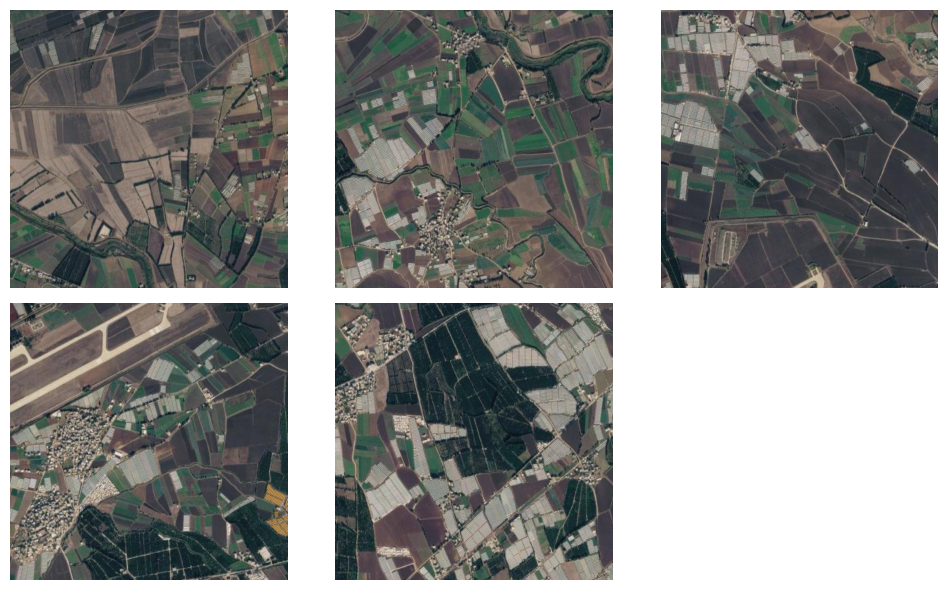

In [13]:
import json
import math

import cv2
from matplotlib import pyplot as plt
import numpy as np
from tqdm import tqdm
from ultralytics.models.sam import SAM3SemanticPredictor

# Initialize predictor with configuration

overrides = {
    "conf": 0.25,
    "task": "segment",
    "mode": "predict",
    "model": "sam3.1_multiplex.pt", # "sam3.pt",
    "quantize": 16,  # Use FP16 for faster inference
    "save": False,
}
predictor = SAM3SemanticPredictor(overrides=overrides)

n_cols = 3
# Dynamically calculate rows needed (unlimited rows)
n_rows = math.ceil(counts / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 3 * n_rows), layout="constrained")

# Flatten axes array for easy iteration (handles 1D or 2D shape safely)
axes = axes.flatten()

ious = []

for i, img in enumerate(img_paths):
    image = cv2.cvtColor(cv2.imread(img), cv2.COLOR_BGR2RGB)
    H, W = image.shape[:2]

    predictor.set_image(img)
    
    results = predictor(text=["greenhouse"])

    res = results[0]

    # Merge all predicted instances into one binary mask
    if res.masks is not None and len(res.masks) > 0:
        pred = res.masks.data.cpu().numpy().any(axis=0)
        pred = to_hw(pred, H, W)
    else:
        pred = np.zeros((H, W), dtype=bool)   # nothing detected -> empty mask

    # score = iou(gt, pred)
    # ious.append(score)

    rgb_img = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
    axes[i].imshow(rgb_img)
    axes[i].axis('off')
    name = os.path.splitext(os.path.basename(img))[0]
    # axes[i].set_title(f'Image {name} | IoU: {score:.3f}', fontsize=9)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# plt.title(f'Mean IoU over {len(ious)} images: {np.mean(ious):.3f}', fontsize=14)
plt.tight_layout()
plt.show()

# print(f'Mean IoU over {len(ious)} images: {np.mean(ious):.3f}')